# Pharmacy Sales — Exploratory Data Analysis & ML

**Goal:** analyze the supplied pharmacy sales dataset and build a baseline model to estimate transaction-line revenue.

> The data contains 50,000 rows and 18 months of transactions. Forecasting with only 18 monthly observations is inherently uncertain. Treat all outputs as exploratory, not production forecasts.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = "../data/pharmacy_sales.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))


Shape: (50000, 27)


,Transaction_ID,Transaction_Date,Branch_ID,Branch_Name,District,Province,Payment_Method,Customer_Gender,Customer_Age,Customer_City,...,Supplier_Name,Prescription_Required,Batch_No,Expiry_Date,Quantity,Unit_Price_LKR,Discount_Rate,Line_Total_LKR,Year,Month
0,1,6/22/2023,5,Pharmacy - Negombo,Gampaha,Western,Card,Female,45,Matara,...,Ceylon Pharma Traders,No,LK6929-39,1/12/2025,4,1936.52,0.12,6816.55,2023,6
1,2,3/27/2023,2,Pharmacy - Kandy City,Kandy,Central,Card,Female,75,Kandy,...,Astron Pharma Supply,No,LK2282-55,4/20/2024,2,2335.56,0.05,4437.56,2023,3
2,3,2/15/2022,7,Pharmacy - Ratnapura,Ratnapura,Sabaragamuwa,Card,Female,20,Matara,...,Softlogic Pharma Distribution,No,LK1809-97,2/10/2023,2,2781.10,0.08,5117.22,2022,2
3,4,3/10/2023,4,Pharmacy - Kurunegala,Kurunegala,North Western,Cash,Female,47,Kandy,...,Union Chemists Supply,No,LK9152-14,8/1/2024,5,1829.65,0.13,7958.98,2023,3
4,5,12/4/2022,4,Pharmacy - Kurunegala,Kurunegala,North Western,Card,Female,19,Matara,...,Softlogic Pharma Distribution,No,LK6182-19,1/28/2024,3,1329.85,0.13,3470.91,2022,12


,dtype
Transaction_ID,int64
Transaction_Date,str
Branch_ID,int64
Branch_Name,str
District,str
Province,str
Payment_Method,str
Customer_Gender,str
Customer_Age,int64
Customer_City,str


## 1. Data quality checks

In [2]:
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], errors="coerce")
df["Expiry_Date"] = pd.to_datetime(df["Expiry_Date"], errors="coerce")
df["Line_Total_LKR"] = pd.to_numeric(df["Line_Total_LKR"], errors="coerce")
df["Discount_Rate"] = pd.to_numeric(df["Discount_Rate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False).head(12).to_frame("missing_count"))
print("Date range:", df["Transaction_Date"].min(), "to", df["Transaction_Date"].max())
print("Unique transaction IDs:", df["Transaction_ID"].nunique())


Duplicate rows: 0


,missing_count
Strength_mg,31236
Transaction_Date,0
Transaction_ID,0
Branch_Name,0
District,0
Province,0
Payment_Method,0
Customer_Gender,0
Customer_Age,0
Customer_City,0


Date range: 2022-01-01 00:00:00 to 2023-06-30 00:00:00
Unique transaction IDs: 50000


## 2. KPI summary

In [3]:
kpis = pd.Series({
    "Total revenue (LKR)": df["Line_Total_LKR"].sum(),
    "Transactions": df["Transaction_ID"].nunique(),
    "Quantity sold": df["Quantity"].sum(),
    "Average discount (%)": df["Discount_Rate"].mean() * 100,
    "Average line revenue (LKR)": df["Line_Total_LKR"].mean()
})
display(kpis.to_frame("value").round(2))


,value
Total revenue (LKR),2.602820e+08
Transactions,5.000000e+04
Quantity sold,1.500390e+05
Average discount (%),7.500000e+00
Average line revenue (LKR),5.205640e+03


## 3. Exploratory charts

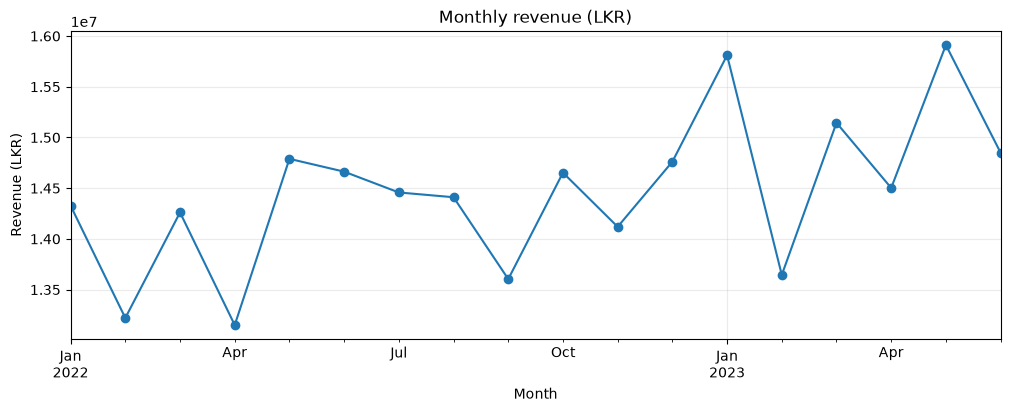

In [ ]:
monthly = (df.dropna(subset=["Transaction_Date"])
           .groupby(pd.Grouper(key="Transaction_Date", freq="MS"))["Line_Total_LKR"]
           .sum())
monthly.plot(figsize=(12,4), marker="o", title="Monthly revenue (LKR)")
plt.xlabel("Month"); plt.ylabel("Revenue (LKR)"); plt.grid(alpha=.25); plt.show()

category_revenue = df.groupby("Medicine_Category")["Line_Total_LKR"].sum().sort_values()
category_revenue.plot(kind="barh", figsize=(8,6), title="Revenue by medicine category")
plt.xlabel("Revenue (LKR)"); plt.show()

branch_revenue = df.groupby("Branch_Name")["Line_Total_LKR"].sum().sort_values(ascending=False)
display(branch_revenue.to_frame("revenue_lkr").round(2))


## 4. Feature engineering and time-aware evaluation

The target is `Line_Total_LKR`. To avoid a random split that mixes earlier and later transactions, the code below sorts by transaction date and holds out the latest 20% of rows. This is a simple baseline; because transaction rows may share dates and the dataset is simulated, interpret metrics cautiously.

In [ ]:
data = df.dropna(subset=["Transaction_Date", "Line_Total_LKR"]).copy()
data["Month"] = data["Transaction_Date"].dt.month
data["Year"] = data["Transaction_Date"].dt.year
feature_cols = ["Quantity", "Unit_Price_LKR", "Discount_Rate", "Customer_Age",
                "Customer_Gender", "Medicine_Category", "Dosage_Form", "Branch_Name", "Month"]
target = "Line_Total_LKR"
data = data.sort_values("Transaction_Date")
split_idx = int(len(data) * 0.8)
train, test = data.iloc[:split_idx], data.iloc[split_idx:]
numeric_features = ["Quantity", "Unit_Price_LKR", "Discount_Rate", "Customer_Age", "Month"]
categorical_features = ["Customer_Gender", "Medicine_Category", "Dosage_Form", "Branch_Name"]
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=150, max_depth=14,
                                        min_samples_leaf=3, random_state=42, n_jobs=-1))
])
model.fit(train[feature_cols], train[target])
pred = model.predict(test[feature_cols])
mae = mean_absolute_error(test[target], pred)
rmse = mean_squared_error(test[target], pred) ** 0.5
r2 = r2_score(test[target], pred)
print(f"Holdout MAE:  LKR {mae:,.2f}")
print(f"Holdout RMSE: LKR {rmse:,.2f}")
print(f"Holdout R²:   {r2:.3f}")


## 5. Inspect actual vs predicted

In [ ]:
comparison = test[["Transaction_Date", "Line_Total_LKR"]].copy()
comparison["Predicted_Revenue_LKR"] = pred
display(comparison.head(20))
plt.figure(figsize=(6,6))
plt.scatter(comparison["Line_Total_LKR"], comparison["Predicted_Revenue_LKR"], alpha=.3)
lims = [min(comparison["Line_Total_LKR"].min(), comparison["Predicted_Revenue_LKR"].min()),
        max(comparison["Line_Total_LKR"].max(), comparison["Predicted_Revenue_LKR"].max())]
plt.plot(lims, lims, "--")
plt.xlabel("Actual revenue (LKR)"); plt.ylabel("Predicted revenue (LKR)")
plt.title("Actual vs predicted"); plt.grid(alpha=.2); plt.show()


## 6. Monthly revenue forecast baseline

This deliberately simple linear trend is a baseline, not a claim of forecast accuracy. With only 18 months, evaluate it against a naive forecast and gather more history before relying on future values.

In [ ]:
from sklearn.linear_model import LinearRegression
monthly_df = monthly.reset_index()
monthly_df.columns = ["MonthStart", "Revenue_LKR"]
monthly_df["t"] = np.arange(len(monthly_df))
trend = LinearRegression().fit(monthly_df[["t"]], monthly_df["Revenue_LKR"])
horizon = 3
future = pd.DataFrame({"t": np.arange(len(monthly_df), len(monthly_df)+horizon)})
future["MonthStart"] = pd.date_range(monthly_df["MonthStart"].max() + pd.offsets.MonthBegin(1),
                                     periods=horizon, freq="MS")
future["Forecast_Revenue_LKR"] = np.maximum(0, trend.predict(future[["t"]]))
display(future[["MonthStart", "Forecast_Revenue_LKR"]].round(2))
plt.figure(figsize=(12,4))
plt.plot(monthly_df["MonthStart"], monthly_df["Revenue_LKR"], marker="o", label="Historical")
plt.plot(future["MonthStart"], future["Forecast_Revenue_LKR"], marker="o", linestyle="--", label="Baseline forecast")
plt.title("Monthly revenue baseline forecast")
plt.ylabel("Revenue (LKR)"); plt.legend(); plt.grid(alpha=.25); plt.show()


## Conclusions & next steps
- Confirm data quality and business definitions before using results externally.
- Keep the chronological holdout metrics with any published model claims.
- Compare against a naive baseline and tune features/model only after establishing a reliable validation setup.
- The transaction model estimates line revenue; the monthly trend is a separate, simple forecast.
- For production, persist the trained model, add tests, monitor data drift, and document the limits of predictions.